# 01 – Data Loading, Cleaning and Visualization
**Project:** AI-Based Smart Traffic Management and Congestion Prediction System
**Dataset:** UCI Metro Interstate Traffic Volume (I-94 Westbound, Minneapolis–St Paul, 2012–2018)

In this notebook we:
1. Load the raw data
2. Understand the columns (data dictionary)
3. Check missing values, duplicates, wrong datatypes and outliers
4. Clean the data and save `Dataset/traffic_clean.csv`
5. Make first visualizations

In [1]:
# Import libraries
import sys
sys.path.append("../src")          # so we can import our own data_preprocessing.py

import numpy as np                 # numbers / arrays
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # plots
import seaborn as sns              # nicer statistical plots

import data_preprocessing as dp    # our cleaning functions

sns.set_theme(style="whitegrid")
IMG = "../Images/"                 # folder where figures are saved

## 1. Load the raw data

In [2]:
raw = dp.load_raw()     # reads Dataset/Metro_Interstate_Traffic_Volume.csv.gz
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 2. Data dictionary

| Column | Type | Description |
|---|---|---|
| holiday | Categorical | US national / regional holiday name (else "None") |
| temp | Numeric (float) | Average temperature in **Kelvin** |
| rain_1h | Numeric (float) | Rain in mm in the hour |
| snow_1h | Numeric (float) | Snow in mm in the hour |
| clouds_all | Numeric (int) | Cloud cover in % |
| weather_main | Categorical | Short weather description (Clear, Clouds, Rain…) |
| weather_description | Categorical | Longer weather description |
| date_time | Datetime | Hour of the record (local CST time) |
| **traffic_volume** | Numeric (int) | **Target** – hourly I-94 westbound traffic volume |

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 5.0 MB


**Observation:** `date_time` is stored as text (`object`) – we must convert it to a real datetime.

In [4]:
# Missing values per column
missing = raw.isna().sum().to_frame("missing_count")
missing["missing_%"] = (missing["missing_count"] / len(raw) * 100).round(2)
missing

,missing_count,missing_%
holiday,48143,99.87
temp,0,0.00
rain_1h,0,0.00
snow_1h,0,0.00
clouds_all,0,0.00
weather_main,0,0.00
weather_description,0,0.00
date_time,0,0.00
traffic_volume,0,0.00


**Observation:** pandas reads the text `"None"` in the `holiday` column as missing. That is **not** truly
missing data – it simply means "not a holiday". All other columns have **no missing values**.

In [5]:
# Holiday values
raw["holiday"].value_counts(dropna=False).head(8)

holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Name: count, dtype: int64

In [6]:
# Duplicates
print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated timestamps (same hour appears more than once):", raw["date_time"].duplicated().sum())

Exact duplicate rows:

 17
Repeated timestamps (same hour appears more than once): 7629


**Observation:** some hours appear several times because the source logs **one row per weather
condition** (e.g. an hour with both *Rain* and *Mist*). The traffic volume is the same in these rows,
so keeping them would count the same hour twice. We keep one row per hour.

In [7]:
# Summary statistics of numeric columns
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
temp,48204.0,281.205870,13.338232,0.0,272.16,282.45,291.806,310.07
rain_1h,48204.0,0.334264,44.789133,0.0,0.00,0.00,0.000,9831.30
snow_1h,48204.0,0.000222,0.008168,0.0,0.00,0.00,0.000,0.51
clouds_all,48204.0,49.362231,39.015750,0.0,1.00,64.00,90.000,100.00
traffic_volume,48204.0,3259.818355,1986.860670,0.0,1193.00,3380.00,4933.000,7280.00


## 3. Outlier inspection
From the summary: `temp` minimum is **0 K** (−273 °C, impossible) and `rain_1h` max is **~9831 mm** in one hour
(impossible). Let's look at box plots.

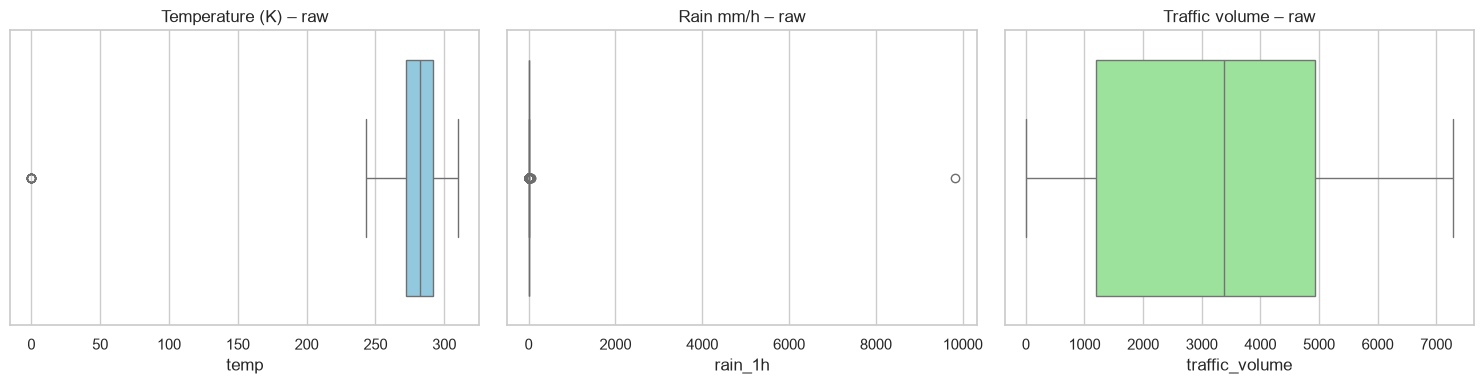

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=raw["temp"], ax=axes[0], color="skyblue").set_title("Temperature (K) – raw")
sns.boxplot(x=raw["rain_1h"], ax=axes[1], color="salmon").set_title("Rain mm/h – raw")
sns.boxplot(x=raw["traffic_volume"], ax=axes[2], color="lightgreen").set_title("Traffic volume – raw")
plt.tight_layout()
plt.savefig(IMG + "01_outliers_raw.png", dpi=120)
plt.show()

In [9]:
print("Rows with temp == 0 K :", (raw["temp"] == 0).sum())
print("Rows with rain > 100 mm:", (raw["rain_1h"] > 100).sum())

Rows with temp == 0 K : 10
Rows with rain > 100 mm: 1


**Decision:** these few rows are sensor errors, so we **drop** them. Traffic volume itself has no
extreme outliers (0 to ~7300 vehicles/hour is realistic), so we keep all its values.

## 4. Clean the data
All cleaning steps are written once in `src/data_preprocessing.py → clean_data()`:
1. Convert `date_time` to datetime
2. Remove exact duplicates
3. Keep one row per hour
4. Remove impossible temperature / rain values
5. Spread the holiday flag to all 24 hours of the holiday (`is_holiday`)
6. Convert temperature from Kelvin to Celsius (`temp_c`)

In [10]:
clean = dp.clean_data(raw)
clean.head()

Start: 48204 rows
Removed 17 exact duplicate rows
Removed 7612 repeated timestamps (multiple weather rows for same hour)
Removed 10 rows with temp = 0 K (sensor error)


Removed 1 rows with impossible rainfall (>100 mm/h)
End: 40564 rows, 9 columns


,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,is_holiday,temp_c
0,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,0,15.13
1,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,0,16.21
2,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,0,16.43
3,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,0,16.98
4,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,0,17.99


In [11]:
clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 40564 entries, 0 to 40563
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   rain_1h              40564 non-null  float64       
 1   snow_1h              40564 non-null  float64       
 2   clouds_all           40564 non-null  int64         
 3   weather_main         40564 non-null  str           
 4   weather_description  40564 non-null  str           
 5   date_time            40564 non-null  datetime64[us]
 6   traffic_volume       40564 non-null  int64         
 7   is_holiday           40564 non-null  int64         
 8   temp_c               40564 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(3), str(2)
memory usage: 3.5 MB


In [12]:
print("Missing values after cleaning:\n", clean.isna().sum())

Missing values after cleaning:
 rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
is_holiday             0
temp_c                 0
dtype: int64


In [13]:
clean.to_csv(dp.CLEAN_PATH, index=False)
print("Saved:", dp.CLEAN_PATH)

Saved: C:\Users\DELL\Desktop\Smart-Traffic-Management-System\Dataset\traffic_clean.csv


## 5. First visualizations

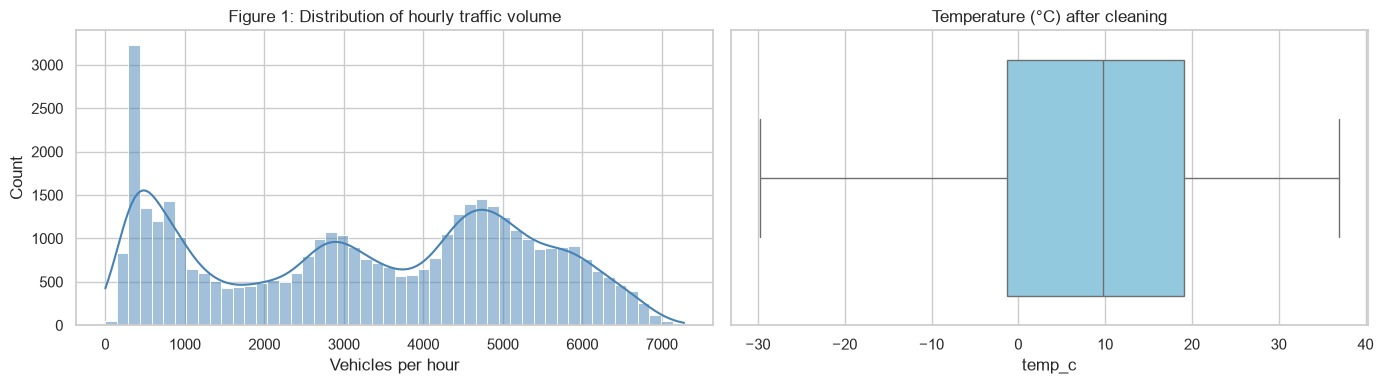

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean["traffic_volume"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Figure 1: Distribution of hourly traffic volume")
axes[0].set_xlabel("Vehicles per hour")
sns.boxplot(x=clean["temp_c"], ax=axes[1], color="skyblue")
axes[1].set_title("Temperature (°C) after cleaning")
plt.tight_layout()
plt.savefig(IMG + "01_volume_distribution.png", dpi=120)
plt.show()

**Interpretation:** the traffic volume distribution is **bimodal** (two peaks): one peak at low
volume (night hours, < 1000) and one wide peak at 4000–6000 (day time). This already suggests that
**hour of day** will be the most important feature.

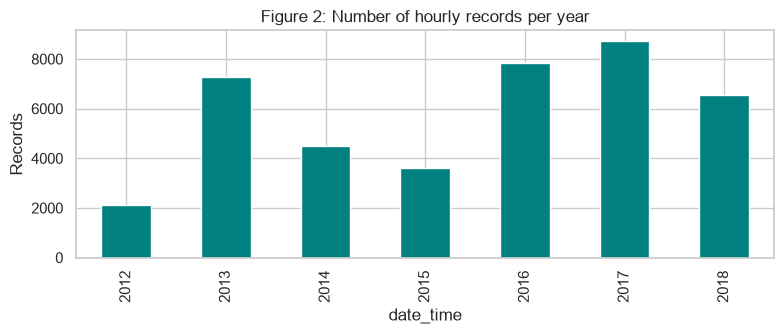

In [15]:
# Records per year – shows a data gap
clean["date_time"].dt.year.value_counts().sort_index().plot(kind="bar", color="teal", figsize=(8, 3.5))
plt.title("Figure 2: Number of hourly records per year")
plt.ylabel("Records")
plt.tight_layout()
plt.savefig(IMG + "01_records_per_year.png", dpi=120)
plt.show()

**Observation:** 2014 and 2015 have fewer records – the sensor had a **data gap** (missing months).
A full year has 8760 hours. We do **not** invent (impute) missing hours, because we would be guessing
traffic; the remaining ~40,000 hours are enough to train our models.

congestion_level
Low       12536
Medium    13515
High      14513
Name: count, dtype: int64 

congestion_level
Low       30.9
Medium    33.3
High      35.8
Name: count, dtype: float64


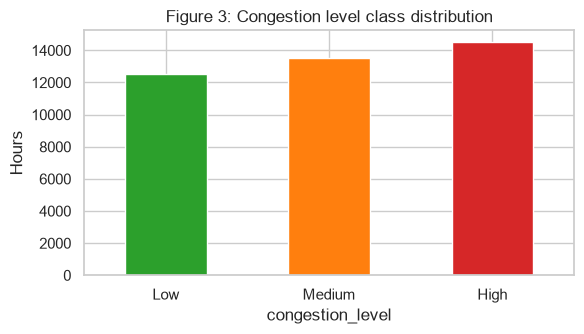

In [16]:
# Congestion class distribution (target for the classification module)
clean["congestion_level"] = dp.make_congestion_label(clean["traffic_volume"])
counts = clean["congestion_level"].value_counts().reindex(dp.CLASS_ORDER)
print(counts, "\n")
print((counts / counts.sum() * 100).round(1))
counts.plot(kind="bar", color=["#2ca02c", "#ff7f0e", "#d62728"], figsize=(6, 3.5), rot=0)
plt.title("Figure 3: Congestion level class distribution")
plt.ylabel("Hours")
plt.tight_layout()
plt.savefig(IMG + "01_class_distribution.png", dpi=120)
plt.show()

**Congestion rule:** Low < 2000 vehicles/h, Medium 2000–4499, High ≥ 4500.
The three classes are **roughly balanced** (about one-third each), so accuracy is meaningful, but we
will still report precision, recall and F1-score per class.